In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
sns.set_theme(style="whitegrid")

iris = load_iris()

df = pd.DataFrame(iris.data,columns=iris.feature_names)

df["species"] = pd.Categorical.from_codes(iris.target,iris.target_names)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

display(df.head())


Dataset loaded successfully!
Dataset shape: (150, 5)
Column names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'species']


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [2]:
print("Dataset dimensions:", df.shape)
print("\nColumn information:")
df.info()
print("\nFirst 10 rows:")
display(df.head(10))
print("\nLast 5 rows:")
display(df.tail())
print("\nNumber of unique values in each column:")
print(df.nunique())

Dataset dimensions: (150, 5)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   sepal length (cm)  150 non-null    float64 
 1   sepal width (cm)   150 non-null    float64 
 2   petal length (cm)  150 non-null    float64 
 3   petal width (cm)   150 non-null    float64 
 4   species            150 non-null    category
dtypes: category(1), float64(4)
memory usage: 5.1 KB

First 10 rows:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
5,5.4,3.9,1.7,0.4,setosa
6,4.6,3.4,1.4,0.3,setosa
7,5.0,3.4,1.5,0.2,setosa
8,4.4,2.9,1.4,0.2,setosa
9,4.9,3.1,1.5,0.1,setosa



Last 5 rows:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica
149,5.9,3.0,5.1,1.8,virginica



Number of unique values in each column:
sepal length (cm)    35
sepal width (cm)     23
petal length (cm)    43
petal width (cm)     22
species               3
dtype: int64


In [3]:
print("Missing values in each column:")
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())
print("\nNumber of duplicate rows:", df.duplicated().sum())
print("\nData types:")
print(df.dtypes)

Missing values in each column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Total missing values: 0

Number of duplicate rows: 1

Data types:
sepal length (cm)     float64
sepal width (cm)      float64
petal length (cm)     float64
petal width (cm)      float64
species              category
dtype: object


In [4]:
print("Statistical summary:")
display(df.describe())
numeric_df = df.select_dtypes(include="number")
summary = pd.DataFrame({
    "Mean": numeric_df.mean(),
    "Median": numeric_df.median(),
    "Standard Deviation": numeric_df.std(),
    "Minimum": numeric_df.min(),
    "Maximum": numeric_df.max(),
    "Range": numeric_df.max() - numeric_df.min()
})
print("\nDetailed statistics:")
display(summary.round(3))

Statistical summary:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000



Detailed statistics:


,Mean,Median,Standard Deviation,Minimum,Maximum,Range
sepal length (cm),5.843,5.80,0.828,4.3,7.9,3.6
sepal width (cm),3.057,3.00,0.436,2.0,4.4,2.4
petal length (cm),3.758,4.35,1.765,1.0,6.9,5.9
petal width (cm),1.199,1.30,0.762,0.1,2.5,2.4


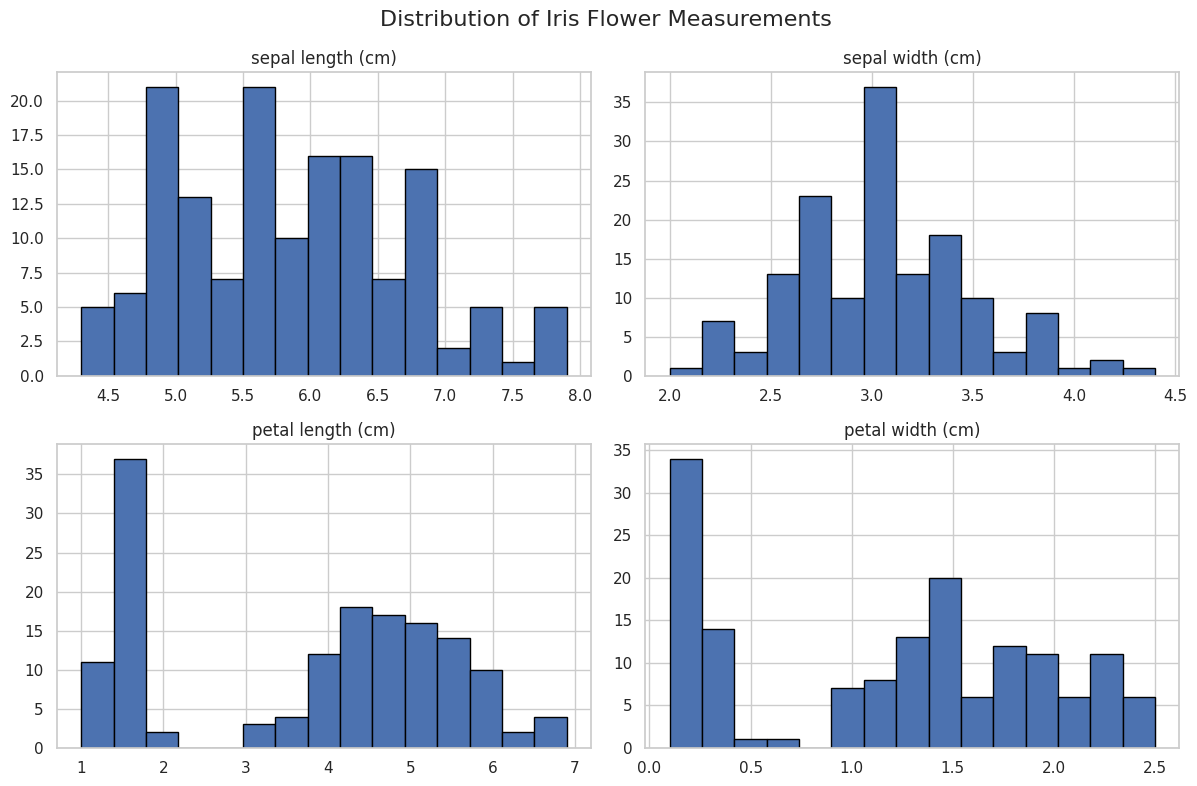

In [5]:
features = iris.feature_names
df[features].hist(figsize=(12, 8),bins=15,edgecolor="black")
plt.suptitle("Distribution of Iris Flower Measurements", fontsize=16)
plt.tight_layout()
plt.show()

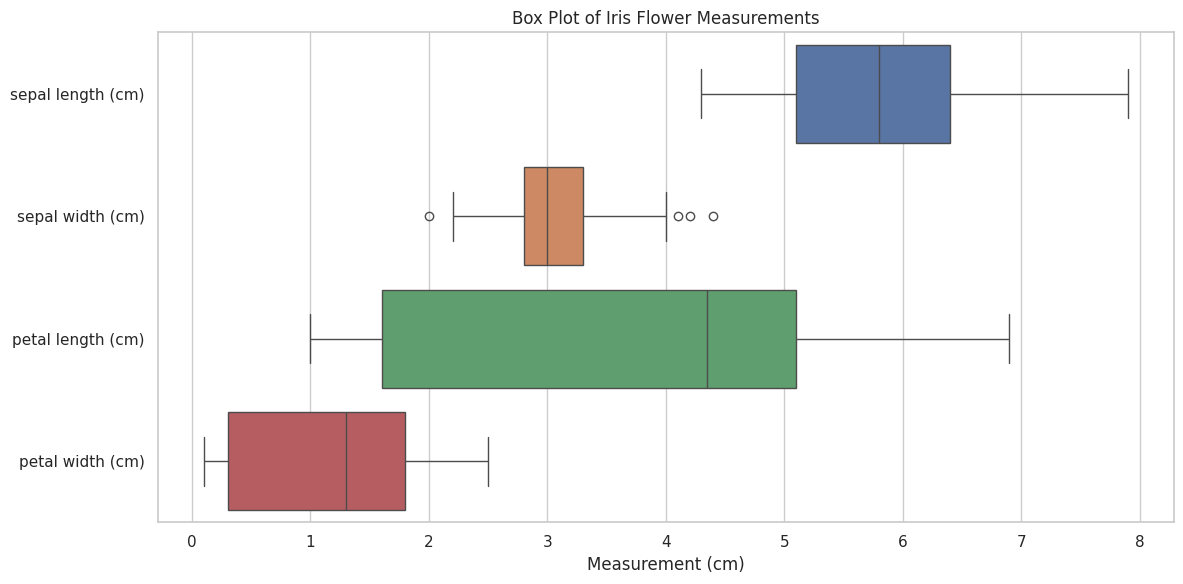

In [6]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[features], orient="h")
plt.title("Box Plot of Iris Flower Measurements")
plt.xlabel("Measurement (cm)")
plt.tight_layout()
plt.show()

Correlation matrix:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000,-0.118,0.872,0.818
sepal width (cm),-0.118,1.000,-0.428,-0.366
petal length (cm),0.872,-0.428,1.000,0.963
petal width (cm),0.818,-0.366,0.963,1.000


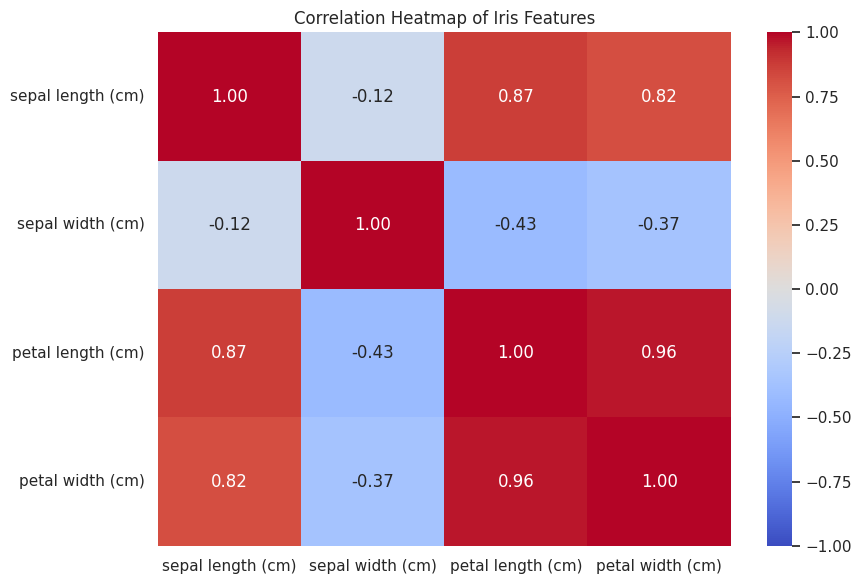

In [7]:
correlation_matrix = df[features].corr()
print("Correlation matrix:")
display(correlation_matrix.round(3))
plt.figure(figsize=(9, 6))
sns.heatmap(correlation_matrix,annot=True,cmap="coolwarm",fmt=".2f",vmin=-1,vmax=1)
plt.title("Correlation Heatmap of Iris Features")
plt.tight_layout()
plt.show()


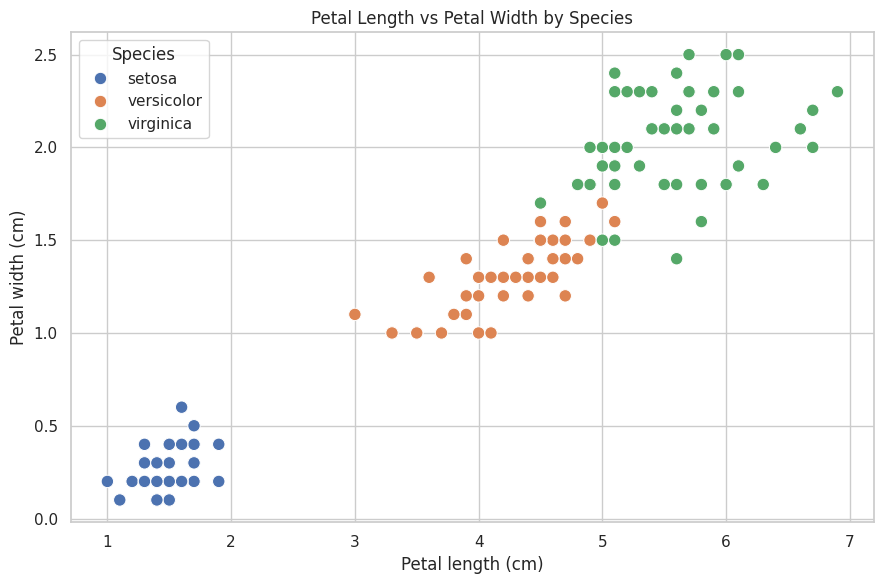

In [8]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="species",
    s=80
)
plt.title("Petal Length vs Petal Width by Species")
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.legend(title="Species")
plt.tight_layout()
plt.show()

In [11]:
print("========== EDA FINDINGS ==========")
print("\n1. Dataset size:")
print(f"{df.shape[0]} rows and {df.shape[1]} columns")
print("\n2. Species counts:")
print(df["species"].value_counts())
print("\n3. Missing values:")
print("Total:", df.isnull().sum().sum())
print("\n4. Average measurements:")
display(df[features].mean().round(3))
corr = df[features].corr()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.stack()
print("\n5. Strongest positive correlation:")
print(pairs.idxmax(), "=", round(pairs.max(), 3))
print("\n6. Strongest negative correlation:")
print(pairs.idxmin(), "=", round(pairs.min(), 3))
print("\n7. Feature with highest standard deviation:")
print(df[features].std().idxmax())
print("\n8. Species with largest average petal length:")
print(df.groupby("species", observed=True)["petal length (cm)"].mean().idxmax())
print("\nEDA completed successfully!")

========== EDA FINDINGS ==========

1. Dataset size:
150 rows and 5 columns

2. Species counts:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

3. Missing values:
Total: 0

4. Average measurements:


,0
sepal length (cm),5.843
sepal width (cm),3.057
petal length (cm),3.758
petal width (cm),1.199



5. Strongest positive correlation:
('petal length (cm)', 'petal width (cm)') = 0.963

6. Strongest negative correlation:
('sepal width (cm)', 'petal length (cm)') = -0.428

7. Feature with highest standard deviation:
petal length (cm)

8. Species with largest average petal length:
virginica

EDA completed successfully!
